# A Basic Statistical Model in PyTorch

## Nearest Neighbors

$f:R \rightarrow \{0, 1\}$
- find closest x in data
- return corresponding y

In [22]:
# Automatically reload external modules when their source files change (handy during development)
%load_ext autoreload
%autoreload 2

import torch  # main library for tensor operations
import torchvision  # datasets and image transforms
from PIL import Image  # reading / displaying images


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Image Visualization
+

In [23]:
# Convert an image tensor into a PIL image so it can be displayed in the notebook
def visualize_image(img):
    # img has shape (C, H, W) with values in [0, 1] -> scale to [0, 255]
    # permute(1, 2, 0) reorders to (H, W, C) because PIL expects channels last
    img = 255 * img.permute(1, 2, 0)
    # cast to uint8 and convert to a numpy array
    img = img.byte().numpy()

    return Image.fromarray(img)

In [24]:
# Take a subset of the dataset, keep only two flower classes and relabel them as 0 and 1
def split_data(dataset, n=100):
    imgs = []
    labels = []

    # Only go through the first ~1000 samples to keep things fast
    for i in range(len(dataset)):
        if i > 1000:
            break

        x, y = dataset[i]  # x: image tensor, y: original label (0..101)
        imgs.append(x)
        labels.append(y)

    # Stack lists into tensors: imgs has shape (N, 3, H, W), labels has shape (N,)
    imgs = torch.stack(imgs, dim=0)
    labels = torch.as_tensor(labels, dtype=torch.long)

    # Pick two flower classes: class 0 (pink) and class 4 (orange)
    l1 = 0
    l2 = 4

    # Boolean mask that keeps only samples from these two classes
    mask = (labels == l1) | (labels == l2)
    imgs = imgs[mask]
    labels = labels[mask]
    # Relabel: l1 -> 0, l2 -> 1 (a binary classification problem)
    labels[labels == l1] = 0
    labels[labels == l2] = 1

    # Return at most the first n samples
    return imgs[:n], labels[:n]

In [25]:
# Target image size: 128x128 pixels
size = (128, 128)
# Compose chains several transforms in order:
#   1) Resize: rescale the image to 128x128
#   2) ToTensor: convert the PIL image to a (C, H, W) tensor with values scaled to [0, 1]
transform = torchvision.transforms.Compose([torchvision.transforms.Resize(size), torchvision.transforms.ToTensor()])

In [26]:
# Load the training split of the Flowers102 dataset (102 flower categories) from ./flowers
# download=False: the data is already on disk, so don't download it again
train_dataset = torchvision.datasets.Flowers102("./flowers", "train", transform=transform, download=False)

In [27]:
# For NN, We'll need to split the data directly into an image tensor and a label tensor
# (KNN doesn't "train": it just stores the training data and compares distances at prediction time)
imgs, labels = split_data(train_dataset)

In [28]:
# Print the shape and dtype of the image tensor
# (N, 3, 128, 128) = N images, 3 RGB channels, height 128, width 128
print(f"{imgs.shape = }")
print(f"{imgs.dtype = }")

imgs.shape = torch.Size([20, 3, 128, 128])
imgs.dtype = torch.float32


In [29]:
# Print the shape and dtype of the label tensor (one label, 0 or 1, per image)
print(f"{labels.shape = }")
print(f"{labels.dtype = }")

labels.shape = torch.Size([20])
labels.dtype = torch.int64


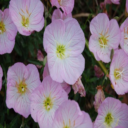

In [30]:
# show a pink flower image (label = 0)
pink = imgs[labels == 0]  # select all images with label 0

visualize_image(pink[0])  # display the first one

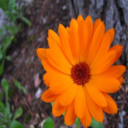

In [31]:
# show a orange image (label = 1)
orange = imgs[labels == 1]  # select all images with label 1

visualize_image(orange[0])  # display the first one

# Nearest Neighbor Classifier

Let us look at a simple classifier called k-nearest neighbor (kNN) classifier.

The idea is the following: given a new point, we predict it label based on the labels from a subset of $k$ training
sample that are *closest* to the new point.

Or put it in a more mathematical way:

We are given a training set $\mathcal{D}=\{(\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), \cdots, (\mathbf{x}_N, y_N)\}$
and a new data point $\mathbf{x}$.

The k-NN classifier is a function $f(\mathbf{x}): \mathbb{R} \rightarrow \{0, 1\} $ that does the following:

(1) it computes the distance of each training sampleto the new point
$\mathbf{x}$: $d_1=|\mathbf{x}_1 - \mathbf{x}|, \cdots, d_N=|\mathbf{x}_N - \mathbf{x}|$;

(2) it sorts $\{ d_1, \cdots, d_N \}$ in ascending order into $\{ d_{i_1}, \cdots, d_{i_k}, \cdots , d_{i_N} \}$,
where $ d_{i_1} < \cdots < d_{i_k} < \cdots < d_{i_N} $;

(3) it predicts the new point's label based on the *mode* of $\{ y_{i_1}, \cdots, y_{i_k} \}$.
(Mode refers to the value that appears most in the set)

$ f(\mathbf{x}) = Mode(\{ y_{i_1}, \cdots, y_{i_k} \}) $

In [32]:
# KNN classification: predict a label by majority vote among the k nearest neighbors
def knn_classify(x_train, y_train, x_input, k=3):
    # Compute distances between x and all examples in the training set
    # (Euclidean: squared difference -> sum over C, H, W -> square root)
    distances = ((x_input - x_train) ** 2).sum(dim=(1, 2, 3)).sqrt()

    # Sort by distance and return indices of the first k neighbors
    k_indices = torch.argsort(distances)[:k]
    # Extract the labels of the k nearest neighbor training samples
    k_nearest_labels = y_train[k_indices]

    # Count how often each label appears and return the most frequent one (the mode)
    (labels, cnts) = torch.unique(k_nearest_labels, return_counts=True)
    idx = torch.argmax(cnts)

    return labels[idx]


# KNN regression: same idea, but return the MEAN of the k neighbors' labels
def knn_regression(x_train, y_train, x_input, k=3):
    # Compute distances between x and all examples in the training set
    distances = ((x_input - x_train) ** 2).sum(dim=(1, 2, 3)).sqrt()

    # Sort by distance and return indices of the first k neighbors
    k_indices = torch.argsort(distances)[:k]
    # Extract the labels of the k nearest neighbor training samples
    k_nearest_labels = y_train[k_indices]

    # Average label (e.g. 0.3 means "somewhat closer to pink than to orange")
    return k_nearest_labels.mean()


# Try a prediction for training image idx=1
idx = 1
prediction = knn_classify(imgs, labels, imgs[idx], k=3)
label = labels[idx]  # ground-truth label

print(f"{prediction = }")
print(f"{label = }")

prediction = tensor(0)
label = tensor(0)


In [33]:
# Wrap KNN in a class so it can be reused for both classification and regression
# (note: "classifipinkion" is a typo from the original notebook for "classification";
#  it is used consistently, so it is kept as-is)
class KNN:
    def __init__(self, x, y, k=3, task="classifipinkion"):
        # "Fitting" a KNN model just means storing the training data
        self.X_train = x
        self.y_train = y

        self.k = k  # number of nearest neighbors to use
        self.task = task  # the type of problem: classification or "regression"

    def predict(self, x):
        # Predict for each image in x and return the results as a tensor
        predicted_labels = [self._predict(x_i).item() for x_i in x]
        return torch.tensor(predicted_labels)

    def _predict(self, x):
        # Compute distances between x and all examples in the training set
        distances = ((x - self.X_train) ** 2).sum(dim=(1, 2, 3)).sqrt()

        # Sort by distance and return indices of the first k neighbors
        k_indices = torch.argsort(distances)[: self.k]
        # Extract the labels of the k nearest neighbor training samples
        k_nearest_labels = self.y_train[k_indices]

        if self.task == "classifipinkion":
            # return the most common class label
            (labels, cnts) = torch.unique(k_nearest_labels, return_counts=True)
            idx = torch.argmax(cnts)
            return labels[idx]

        elif self.task == "regression":
            # return the mean of the labels
            return torch.mean(torch.tensor(k_nearest_labels).float())


# Fit the KNN model with the training data (k=3, classification)
knn = KNN(imgs, labels, k=3, task="classifipinkion")

# Predict image idx=1 (imgs[idx : idx + 1] keeps a batch dimension of size 1)
idx = 1
prediction = knn.predict(imgs[idx : idx + 1])
label = labels[idx]  # ground-truth label

print(f"{prediction = }")
print(f"{label = }")

prediction = tensor([0])
label = tensor(0)


## Testing the Model

len(imgs_test) = 65
Ground truth label:  0
Predicted label:  tensor(0)


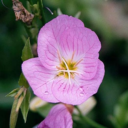

In [34]:
# Load the test split (data the model has never seen) and process it like the training data
test_dataset = torchvision.datasets.Flowers102("./flowers", "test", transform=transform)
imgs_test, labels_test = split_data(test_dataset)

print(f"{len(imgs_test) = }")  # number of test images
print("Ground truth label: ", labels_test[0].item())  # true label of the first test image
print("Predicted label: ", knn.predict(imgs_test)[0])  # label predicted by the model

visualize_image(imgs_test[0])  # show the first test image

## Quantifying Performance

In [35]:
# Predict the whole test set, then compute accuracy
preds = knn.predict(imgs_test)
# accuracy = number of correct predictions / total number of test images
accuracy = (preds == labels_test).sum() / len(labels_test)

print("Accuracy: ", accuracy.item())

Accuracy:  0.9384615421295166


# Nearest Neighbor Regression

We can also use the Nearest Neighbor model for regression.

The difference is that we use the average of the nearest neighbors' labels as the prediction.

Recall that we use the label 0 for pinks and 1 for oranges. Instead of make this a classifipinkion problem,
we can make it a regression problem.

Here we try to regress to value (orangeness): the probability of being a orange (1) instead of a pink (0).

In this way, we can test on images that are not pinks or oranges and see their orangeness.

## Load and fit the KNN regressor

In [36]:
# Fit the KNN regression model with the training data
# We use K=10 to get a smoother regression result (more neighbors are averaged)

knn = KNN(imgs, labels, k=10, task="regression")

## Test the model on pink/orange flowers

In [37]:
# Index of the first test image of the pink class (0) and of the orange class (1)
pink_idx = labels_test[labels_test == 0][0]
orange_idx = labels_test[labels_test == 1][0]

# Check the prediction on a pink flower: a value close to 0 is good
print("Ground truth label: ", labels[pink_idx].item())
print("Predicted label: ", knn.predict(imgs_test[pink_idx : pink_idx + 1]).item())

# Check the prediction on an orange flower: a value close to 1 is good
print("Ground truth label: ", labels[orange_idx].item())
print("Predicted label: ", knn.predict(imgs_test)[orange_idx : orange_idx + 1].item())

Ground truth label:  0
Predicted label:  0.20000000298023224
Ground truth label:  0
Predicted label:  0.4000000059604645


C:\Users\HP\AppData\Local\Temp\ipykernel_25248\2666740071.py:35: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.mean(torch.tensor(k_nearest_labels).float())


## Inference on out-of-domain images

In [38]:
import torchvision.transforms as transforms


# Load any image from disk and convert it to a tensor in the same format as the training data
def load_image_to_tensor(filename):
    # Must resize to the same size (128x128) as the training data, otherwise KNN can't compute distances
    transform = transforms.Compose([transforms.Resize(size), transforms.ToTensor()])
    # convert("RGB") guarantees exactly 3 color channels
    image = Image.open(filename).convert("RGB")
    return transform(image)


# An "out-of-domain" image (neither a pink nor an orange flower) to see how the model reacts
penguin_img = load_image_to_tensor("flowers/flowers-102/jpg/image_00029.jpg")

# The model is in regression mode -> the output is an "orangeness" score between 0 and 1
print("Predicted label: ", knn.predict([penguin_img]).item())

Predicted label:  0.30000001192092896


C:\Users\HP\AppData\Local\Temp\ipykernel_25248\2666740071.py:35: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.mean(torch.tensor(k_nearest_labels).float())
